# Figure 3 v2
4-row, 3-column (dataset) figure. Row A: LOO improvement over the no-history baseline, by bias mechanism (unchanged). Row B: heatmap of Pearson correlations between three DDM choice-history parameters and the two behavioral choice-history effects. Rows C-D: the same two correlations as scatterplots. Refactored from the earlier bivariate-outlier-robust (skipped) correlation version to plain Pearson r + a JZS Bayes Factor (BF10); BF10 evidence category (for/inconclusive/against a correlation) is color-coded consistently across the heatmap and both scatterplot rows.

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_subj_params,
    load_choicehistorypersubject_betas,
    load_rtlme_switchpersubject_betas,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-full"

RT_CORR_COLOR = "#4C72B0"

### Helper functions
`pearson_corr_bf` computes the Pearson correlation (r, p-value) and the JZS Bayes Factor (BF10, via `pingouin.corr`), classifies the evidence into one of three categories using the standard Jeffreys/Kass-Raftery convention (BF10 > 3: evidence for a correlation; 1/3 <= BF10 <= 3: inconclusive; BF10 < 1/3: evidence for the null, i.e. against a correlation), and fits a plain OLS line + 95% CI band on every point (no outlier exclusion, unlike the previous skipped-correlation version). `plot_pearson_corr` draws the scatter/line/CI colored by that evidence category and annotates r/p/BF10.

In [2]:
BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#2CA02C",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#6A51A3",
}
def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"


def format_bf(bf10):
    if bf10 >= 1000 or bf10 <= 0.001:
        return f"{bf10:.2e}"
    return f"{bf10:.2f}"


def pearson_corr_bf(x, y):
    """Pearson r/p plus the JZS Bayes Factor (BF10), and an OLS line + 95%
    CI band fit on every point (no outlier exclusion)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    res = pg.corr(x, y, method="pearson")
    r = float(res["r"].iloc[0])
    pval = float(res["p_val"].iloc[0])
    bf10 = float(res["BF10"].iloc[0])
    category = bf_category(bf10)

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "bf10": bf10,
        "category": category,
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def plot_pearson_corr(ax, x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = pearson_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
               linewidth=0.5, s=40, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                     color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
            linestyle="--", zorder=4)

    ax.text(0.05, 0.95,
            f"r = {result['r']:.2f}, p = {result['pval']:.3g}\n"
            f"BF10 = {format_bf(result['bf10'])}, n = {result['n']}",
            transform=ax.transAxes, ha="left", va="top", fontsize=9,
            color=color, fontweight="bold")

    return result


BF_LOG10_CAP = 5  # log10(BF10) = 5, i.e. BF10 = 1e5; finer resolution beyond
                  # this isn't meaningful (same rationale as the earlier
                  # -log10(p) cap in the previous version of this heatmap)

# Diverging colormap for the heatmap: evidence-against -> inconclusive ->
# evidence-for, using the same 3 anchor colors as the categorical BF_COLORS
# used for the scatterplot panels, so the two rows read consistently.
bf_diverging_cmap = mpl.colors.LinearSegmentedColormap.from_list(
    "bf_diverging",
    [BF_COLORS["evidence_against"], BF_COLORS["inconclusive"], BF_COLORS["evidence_for"]],
)
bf_diverging_norm = mpl.colors.Normalize(vmin=-BF_LOG10_CAP, vmax=BF_LOG10_CAP)



### 4x3 figure: LOO improvement, DDM-parameter x behavior heatmap, and two correlation scatterplots
Columns = datasets (labeled on the top row only). Row A: LOO improvement over the no-history baseline, by bias mechanism, in the fixed order Valuation, Drift, Stp, Full (unchanged from the previous version). Row B: heatmap of Pearson correlations between three DDM choice-history parameters from `HDDM_Base_Lag1-full` (`z_choice_prev1`, `v_choice_prev1`, and the per-subject valuation-bias difference `lambda_accept - lambda_reject`, the per-subject analog of the group-level quantity in `figure3.ipynb`) and the two behavioral choice-history effects (`choice_prev1_effect` on gamble acceptance, `switch_effect` on RT); cell color is the BF10 evidence category (see legend), cell text is the Pearson r. Row C: `choice_prev1_effect` vs. `v_choice_prev1` (drift bias). Row D: `switch_effect` vs. `z_choice_prev1` (starting-point bias). Rows C-D use `plot_pearson_corr` -- Pearson r/BF10 on every subject (no outlier exclusion), colored by the same BF10 evidence category as the heatmap.

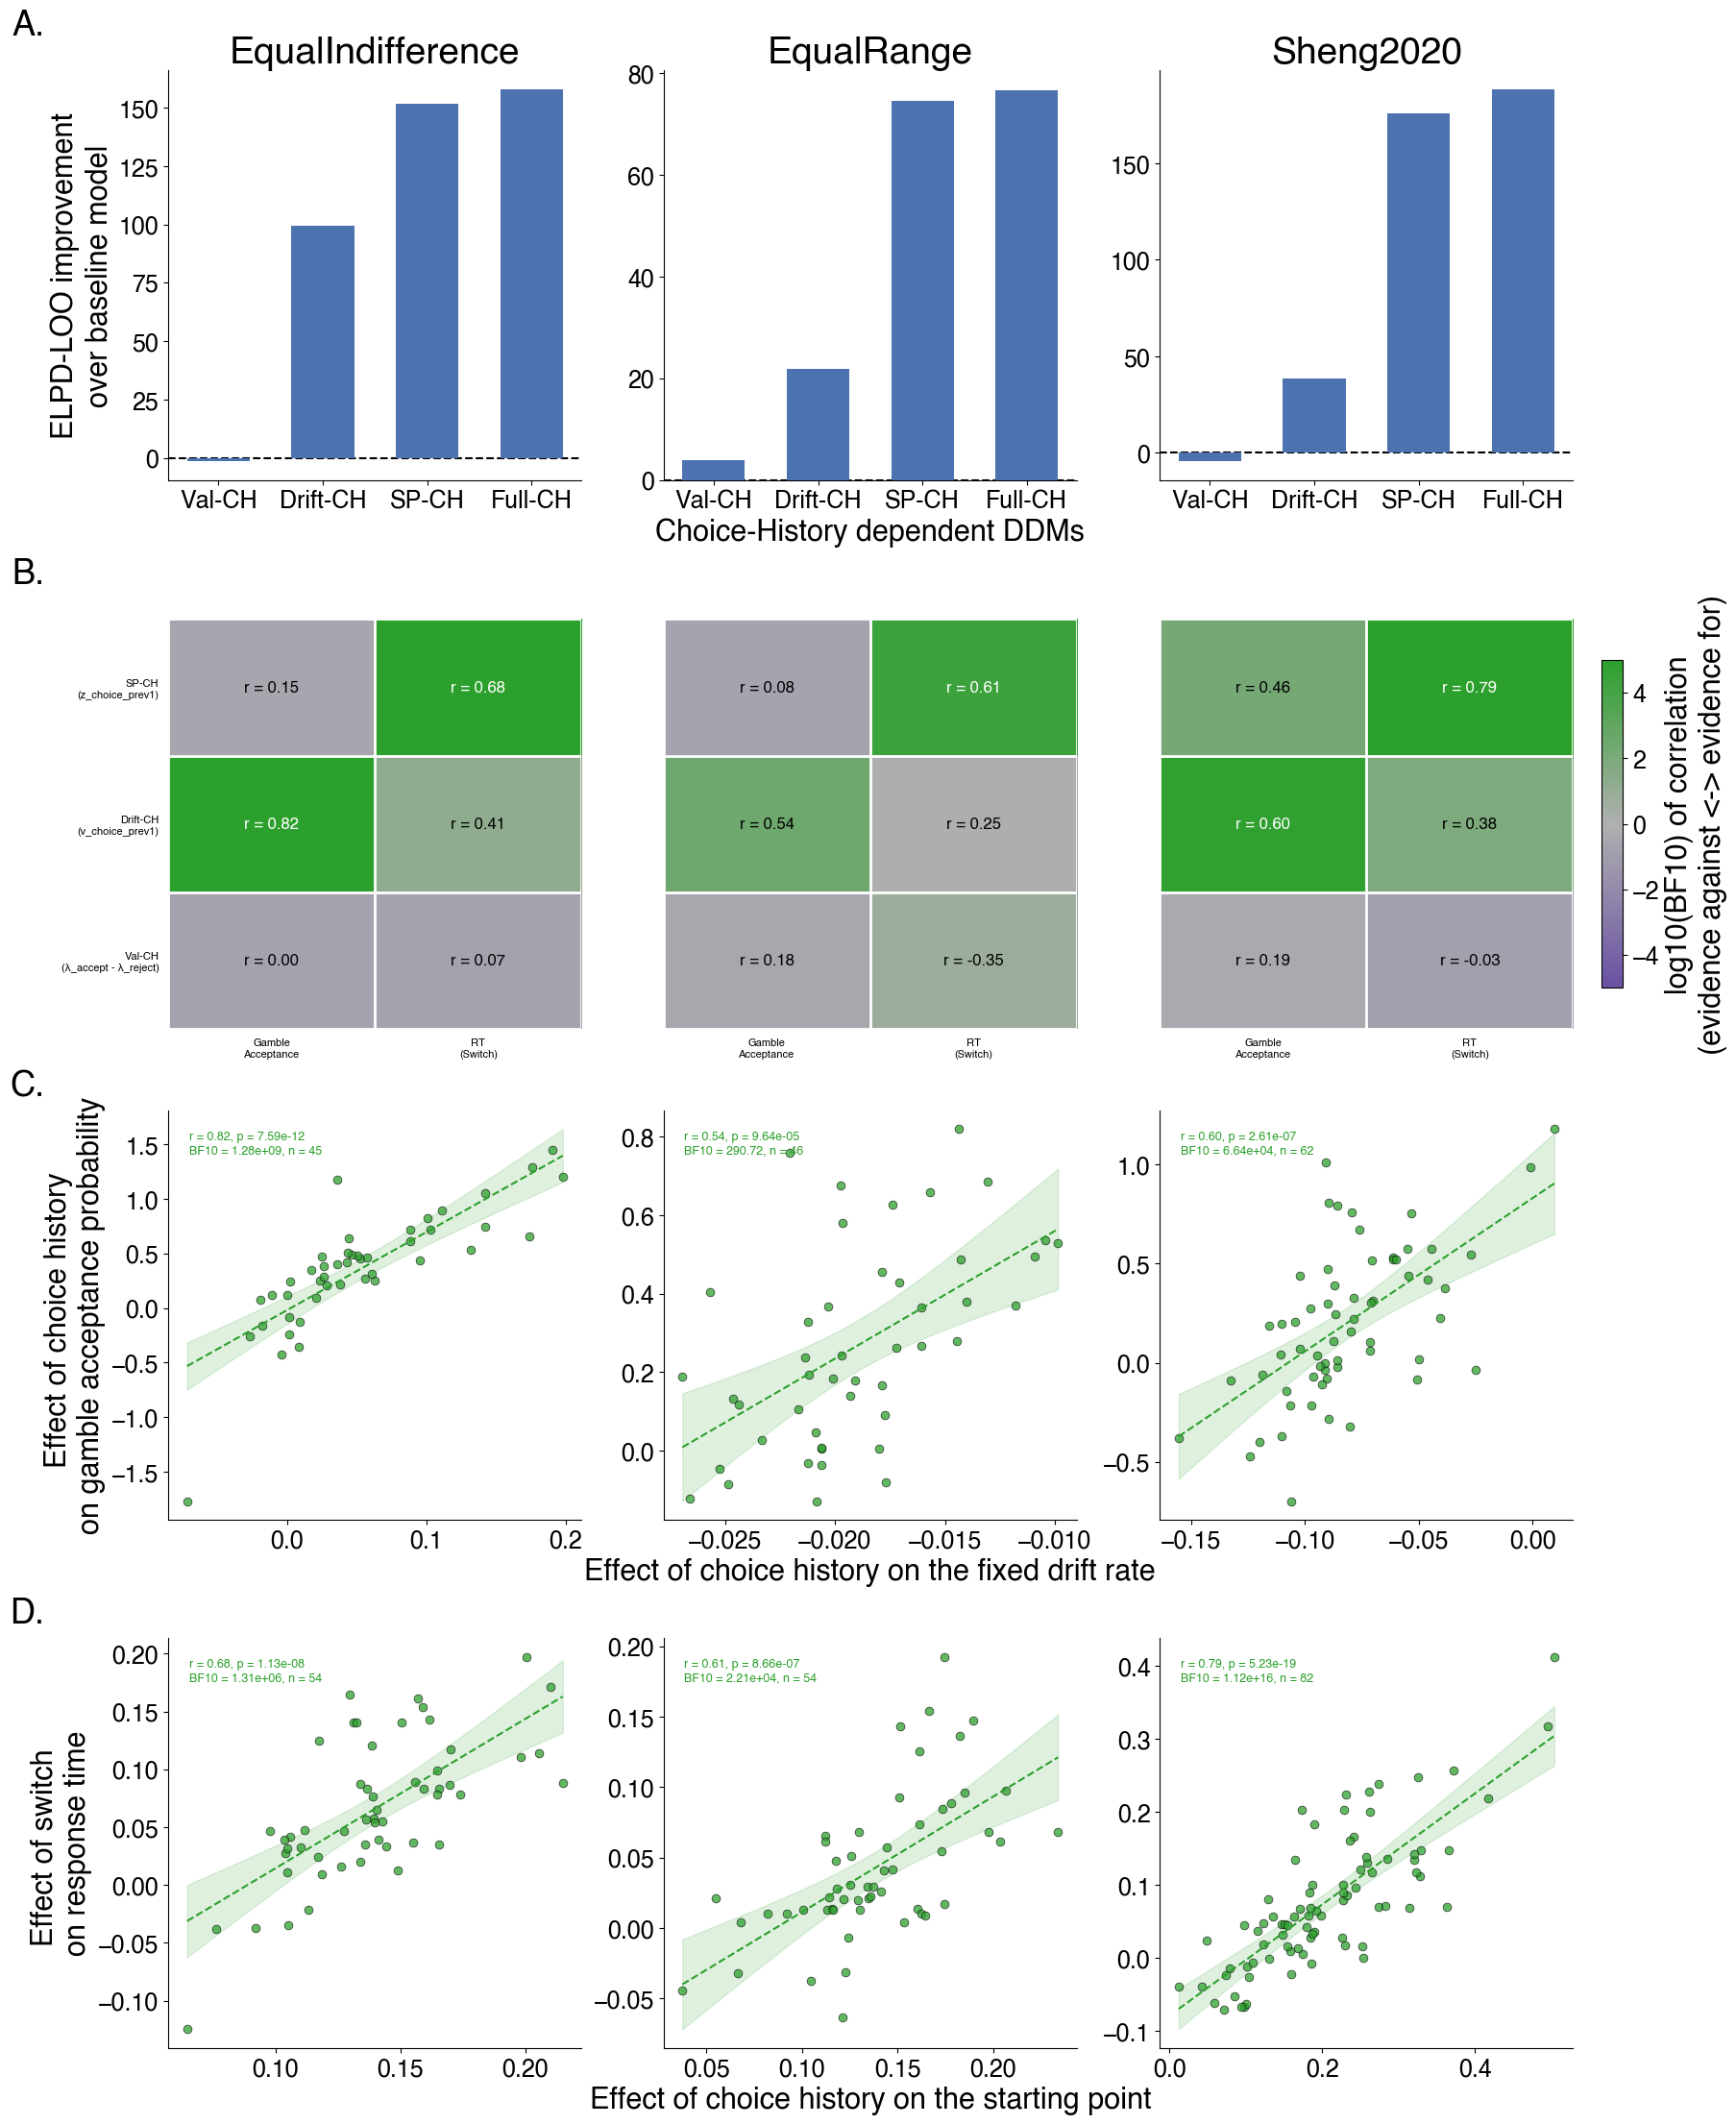

In [3]:
BASELINE_MODEL = "HDDM_Base"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stim",  "Val-CH"),
    ("HDDM_Base_Lag1-drift", "Drift-CH"),
    ("HDDM_Base_Lag1-stp",   "SP-CH"),
    ("HDDM_Base_Lag1-full",  "Full-CH"),
]

DDM_PARAM_SPECS = [
    ("z_choice_prev1", "SP-CH\n(z_choice_prev1)"),
    ("v_choice_prev1", "Drift-CH\n(v_choice_prev1)"),
]

BEHAVIOR_SPECS = [
    ("choice_prev1_effect", "Gamble\nAcceptance"),
    ("switch_effect", "RT\n(Switch)"),
]

elpd_vs_baseline = {}
for ds in DATASETS:
    # The 5 models needed here (Base, stim, drift, stp, full) are split
    # across two LOO comparison groups; HDDM_Base's elpd_loo matches
    # exactly between them (same model, same data), so it's safe to
    # concatenate and drop the duplicate.
    loo_onemech = load_loo_comparison(ds, group_name="choicehistory_onemechanism")
    loo_best = load_loo_comparison(ds, group_name="choicehistory_bestmodel")
    loo = (pd.concat([loo_onemech, loo_best])
           .drop_duplicates(subset="model")
           .set_index("model")["elpd_loo"])
    baseline_elpd = loo[BASELINE_MODEL]
    elpd_vs_baseline[ds] = [loo[m] - baseline_elpd for m, _ in ELPD_MODEL_ORDER]

choicehistory_betas = load_choicehistorypersubject_betas()
choicehistory_betas = choicehistory_betas[choicehistory_betas["converged"]]

switch_betas = load_rtlme_switchpersubject_betas()
switch_betas = switch_betas[switch_betas["converged"]]

drift_vs_choice = {}
z_vs_switch = {}
heatmap_data = {}

for ds in DATASETS:
    full_params = (load_ddm_subj_params(FULL_DDM_MODEL, ds)
                   .pivot(index="sub", columns="param_name", values="param_value"))

    beh_ds = (choicehistory_betas[choicehistory_betas["dataset"] == ds]
              .set_index("sub")["choice_prev1_effect"])
    switch_ds = (switch_betas[switch_betas["dataset"] == ds]
                 .set_index("sub")["switch_effect"])

    drift_vs_choice[ds] = pd.concat(
        [full_params["v_choice_prev1"].rename("v_choice_prev1"),
         beh_ds.rename("choice_prev1_effect")], axis=1, join="inner",
    )
    z_vs_switch[ds] = pd.concat(
        [full_params["z_choice_prev1"].rename("z_choice_prev1"),
         switch_ds.rename("switch_effect")], axis=1, join="inner",
    )

    # Per-subject analog of the group-level lambda_accept - lambda_reject
    # (Valuation Bias) used in the posterior-samples figure (figure3.ipynb).
    lambda_accept = ((full_params["v_loss_centered"] + full_params["v_loss_centered:choice_prev1"]) /
                      (full_params["v_gain_centered"] + full_params["v_gain_centered:choice_prev1"]))
    lambda_reject = ((full_params["v_loss_centered"] - full_params["v_loss_centered:choice_prev1"]) /
                      (full_params["v_gain_centered"] - full_params["v_gain_centered:choice_prev1"]))
    full_params["valuation_bias_diff"] = lambda_accept - lambda_reject

    ddm_specs = DDM_PARAM_SPECS + [
        ("valuation_bias_diff", "Val-CH\n(\u03bb_accept - \u03bb_reject)"),
    ]
    behavior_values = {"choice_prev1_effect": beh_ds, "switch_effect": switch_ds}

    r_mat = np.full((len(ddm_specs), len(BEHAVIOR_SPECS)), np.nan)
    log10_bf_mat = np.full((len(ddm_specs), len(BEHAVIOR_SPECS)), np.nan)

    for i, (ddm_col, _) in enumerate(ddm_specs):
        for j, (beh_col, _) in enumerate(BEHAVIOR_SPECS):
            merged = pd.concat(
                [full_params[ddm_col].rename("ddm"), behavior_values[beh_col].rename("beh")],
                axis=1, join="inner",
            ).dropna()
            result = pearson_corr_bf(merged["ddm"].values, merged["beh"].values)
            r_mat[i, j] = result["r"]
            log10_bf_mat[i, j] = np.clip(np.log10(result["bf10"]), -BF_LOG10_CAP, BF_LOG10_CAP)

    heatmap_data[ds] = {
        "r": r_mat,
        "log10_bf": log10_bf_mat,
        "ddm_labels": [lbl for _, lbl in ddm_specs],
    }

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(18, 22), layout="constrained")

x_pos = np.arange(len(ELPD_MODEL_ORDER))
x_labels = [label for _, label in ELPD_MODEL_ORDER]

# --- Row A: LOO improvement over baseline ---
for col, ds in enumerate(DATASETS):
    ax = axes[0, col]
    diffs = elpd_vs_baseline[ds]

    ax.bar(x_pos, diffs, color=RT_CORR_COLOR, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    if col == 0:
        ax.set_ylabel("ELPD-LOO improvement\nover baseline model")
    if col == 1:
        ax.set_xlabel("Choice-History dependent DDMs")

# --- Row B: DDM parameter x behavior correlation heatmap ---
beh_labels = [lbl for _, lbl in BEHAVIOR_SPECS]

for col, ds in enumerate(DATASETS):
    ax = axes[1, col]
    r_mat = heatmap_data[ds]["r"]
    log10_bf_mat = heatmap_data[ds]["log10_bf"]
    ddm_labels = heatmap_data[ds]["ddm_labels"]

    ax.imshow(log10_bf_mat, cmap=bf_diverging_cmap, norm=bf_diverging_norm, aspect="auto")

    for i in range(r_mat.shape[0]):
        for j in range(r_mat.shape[1]):
            cell_rgba = bf_diverging_cmap(bf_diverging_norm(log10_bf_mat[i, j]))
            luminance = 0.299 * cell_rgba[0] + 0.587 * cell_rgba[1] + 0.114 * cell_rgba[2]
            text_color = "white" if luminance < 0.5 else "black"
            ax.text(j, i, f"r = {r_mat[i, j]:.2f}", ha="center", va="center",
                    color=text_color, fontsize=12, fontweight="bold")

    ax.set_xticks(range(len(beh_labels)))
    ax.set_xticklabels(beh_labels, fontsize=8)
    ax.set_yticks(range(len(ddm_labels)))
    ax.set_yticklabels(ddm_labels if col == 0 else [], fontsize=8)

    ax.set_xticks(np.arange(-0.5, len(beh_labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ddm_labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_visible(False)

bf_colorbar = fig.colorbar(
    mpl.cm.ScalarMappable(norm=bf_diverging_norm, cmap=bf_diverging_cmap),
    ax=axes[1, :], shrink=0.8, pad=0.02, aspect=15,
)
bf_colorbar.set_label("log10(BF10) of correlation\n(evidence against <-> evidence for)")

# --- Row C: behavioral choice-history effect vs. DDM drift bias ---
for col, ds in enumerate(DATASETS):
    ax = axes[2, col]
    merged = drift_vs_choice[ds]
    plot_pearson_corr(ax, merged["v_choice_prev1"].values, merged["choice_prev1_effect"].values)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0:
        ax.set_ylabel("Effect of choice history \non gamble acceptance probability")
    if col == 1:
        ax.set_xlabel("Effect of choice history on the fixed drift rate")

# --- Row D: RT switch effect vs. DDM starting-point bias ---
for col, ds in enumerate(DATASETS):
    ax = axes[3, col]
    merged = z_vs_switch[ds]
    plot_pearson_corr(ax, merged["z_choice_prev1"].values, merged["switch_effect"].values)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0:
        ax.set_ylabel("Effect of switch \non response time")
    if col == 1:
        ax.set_xlabel("Effect of choice history on the starting point")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.3, 1.15, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.3, 1.15, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[2, 0].text(-0.3, 1.1, "C.", transform=axes[2, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[3, 0].text(-0.3, 1.1, "D.", transform=axes[3, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3_v2.svg", dpi=300, bbox_inches="tight")

plt.show()
